<a href="https://colab.research.google.com/github/MhiyaJ/My-GIS-Stuff/blob/main/CCHSDistrict(userblockerror).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTING PROGRAMS

Source: theaok.github.io/gisPy/, map.ipynb, Retrieved October 20, 2026

In [ ]:
%%capture

import os, zipfile
import pandas as pd #
import matplotlib.pyplot as plt

import geopandas as gpd

import mapclassify

import seaborn as sns

import folium

from matplotlib.patches import Ellipse

from matplotlib.patheffects import withStroke

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files

from geopandas.tools import geocode

from google.colab.data_table import DataTable
DataTable.max_columns = 250

gpd.__version__

In [ ]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Secondary_-5568767075062576326.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njrhs = gpd.read_file('School_Districts_Secondary.shp')

In [ ]:
njrhs.columns

In [ ]:
njrhs.head(3)

In [ ]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njrhs["NJDOE_ID_S"] = njrhs["NJDOE_ID_S"].astype(str)
njrhs[["CountyCode", "DistrictCode"]] = njrhs["NJDOE_ID_S"].str.extract(r"(\d{2}).*(\d{4})")

#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njrhs2 = njrhs[njrhs['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID', 'geometry']]
njrhs2['DistrictCode']=njrhs2.DistrictCode.str.strip()

njrhs2.rename(columns={'DIST_NAME' : 'District'}, inplace=True)
njrhs2['District'] = njrhs2['District'].str.upper()
njrhs2["District"] = njrhs2["District"].str.replace(" REGIONAL SCHOOL DISTRICT", "")

njrhs2

In [ ]:
njrhs2.plot()

In [ ]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Unified_7341673536716239500.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njsch = gpd.read_file('School_Districts_Unified.shp')

In [ ]:
njsch.columns

In [ ]:
njsch.head(5)

In [ ]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njsch["NJDOE_ID_U"] = njsch["NJDOE_ID_U"].astype(str)
njsch[["CountyCode", "DistrictCode"]] = njsch["NJDOE_ID_U"].str.extract(r"(\d{2}).*(\d{4})")

#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njsch2=njsch[njsch['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID','geometry']]
njsch2['DistrictCode']=njsch2.DistrictCode.str.strip()

njsch2.rename(columns={'DIST_NAME' : 'District'}, inplace=True)
njsch2['District'] = njsch2['District'].str.upper()
njsch2['District'] = njsch2['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
njsch2['District'] = njsch2['District'].str.replace("LAWNSIDE SCHOOL DISTRIC", "LAWNSIDE SCHOOL DISTRICT")
njsch2["District"] = njsch2["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
njsch2["District"] = njsch2["District"].str.replace(" SCHOOL DISTRICT", "")
njsch2["District"] = njsch2["District"].str.replace(" BOARD OF EDUCATION", "")

njsch2

In [ ]:
njsch2.plot()

In [ ]:
fig, ax = plt.subplots(1, figsize=(10,10))
njsch2.plot(ax=ax, color='orange', edgecolor='black',linewidth=1)
njrhs2.plot(ax=ax, color='red', edgecolor='black',linewidth=1)

texts = []
for x, y, label in zip(njsch2.geometry.centroid.x, njsch2.geometry.centroid.y, njsch2.District):
       #Keep label names brief by stripping common suffixes to reduce overlap further
    display_label = label.replace(" Public School District", "").replace(" School District", "").replace(" Board Of Education", "")
    t = ax.text(x, y, display_label, fontsize=7, color='black', fontweight='bold',
                horizontalalignment='center', verticalalignment='center')
    t.set_path_effects([withStroke(linewidth=3, foreground='white')])
    texts.append(t)

for x, y, label in zip(njrhs2.geometry.centroid.x, njrhs2.geometry.centroid.y, njrhs2.District):
       #Keep label names brief by stripping common suffixes to reduce overlap further
    display_label = label.replace(" Public School District", "").replace(" School District", "").replace(" Board Of Education", "")
    t = ax.text(x, y, display_label, fontsize=7, color='black', fontweight='bold',
                horizontalalignment='center', verticalalignment='center')
    t.set_path_effects([withStroke(linewidth=3, foreground='white')])
    texts.append(t)

# Automatically resolve all overlaps
adjust_text(texts, arrowprops=dict(arrowstyle="-", color='gray', lw=0.5))

ax.title.set_text("UNIFIED & SECONDARY SCHOOL DISTRICTS")
ax.set_xticks([])
ax.set_yticks([])
ax.margins(0.04)
ax.axis("off")
plt.show()

In [ ]:
PrgXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/After%20School%20Programs.2.xlsx')

In [ ]:
PrgXls.head()

In [ ]:
#Rename columns and separated program types
PrgXls = PrgXls.rename(columns={'Unnamed: 2': 'Prog Type'})
PrgXls

In [210]:
#Prompted Gemini to fix error due to length of after school program list

# Combine 'Address' and 'City' into a single string for better geocoding accuracy
full_addresses = PrgXls['Address'].astype(str) + ", New Jersey"

# Geocode using 'arcgis' provider to avoid Nominatim's strict 429 rate limiting
geo = geocode(full_addresses, provider='arcgis', timeout=10)
geo.head(3)

,geometry,address
0,POINT (-75.06635 39.9196),"265 Lincoln Ave, Collingswood, New Jersey, 08108"
1,POINT (-75.08938 39.91174),"400 Comly Ave, Oaklyn, New Jersey, 08107"
2,POINT (-75.07578 39.91817),"480 Haddon Ave, Collingswood, New Jersey, 08108"


In [211]:
#PrgXls=gpd.GeoDataFrame(cchs,geometry='geometry'), didn't run therefore prompted Gemini to explain and fix error
# Assign the geocoded geometry to the main DataFrame
PrgXls['geometry'] = geo['geometry']

# Convert to a GeoDataFrame using the new geometry column
PrgXls = gpd.GeoDataFrame(PrgXls, geometry='geometry')

# End of Gemini assistance

#Strip to categorize
PrgFsc = PrgXls[PrgXls['Prog Type'].str.strip() == 'Family Success Center']
PrgCom = PrgXls[PrgXls['Prog Type'].str.strip() == 'Community Center']
PrgGen = PrgXls[PrgXls['Prog Type'].str.strip() == 'General']
PrgHea = PrgXls[PrgXls['Prog Type'].str.strip() == 'Health']

PrgXls.head(3)

,After School Programs,Address,Prog Type,geometry
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health,POINT (-75.06635 39.9196)
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health,POINT (-75.08938 39.91174)
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health,POINT (-75.07578 39.91817)


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

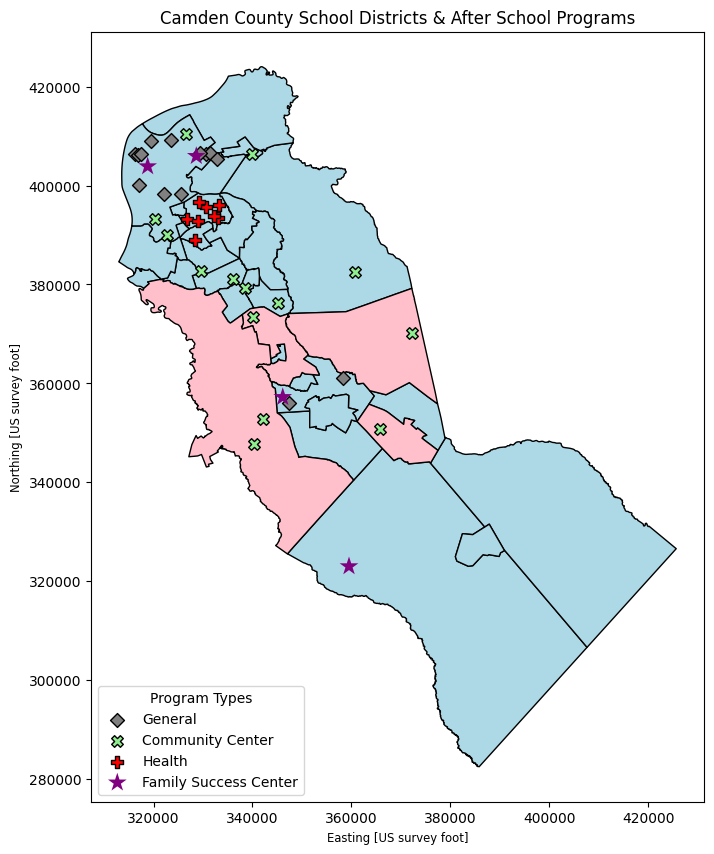

In [212]:
# Project the program layers to match the coordinate reference system of the school districts
PrgGen_proj = PrgGen.to_crs(njsch2.crs)
PrgCom_proj = PrgCom.to_crs(njsch2.crs)
PrgHea_proj = PrgHea.to_crs(njsch2.crs)
PrgFsc_proj = PrgFsc.to_crs(njsch2.crs)

# Original run
fig, ax = plt.subplots(1, figsize=(10,10))

njsch2.plot(ax=ax, color='lightblue', edgecolor='black',linewidth=1)
njrhs2.plot(ax=ax, color='pink', edgecolor='black',linewidth=1)

# Prompted Gemini to create two legends
# Save the first legend (District Type) to prevent it from being overwritten
District_legend = ax.get_legend()

PrgGen_proj.plot(ax=ax, marker='D', color='grey', markersize=50, label='General', edgecolor='black')
PrgCom_proj.plot(ax=ax, marker='X', color='lightgreen', markersize=70, label='Community Center', edgecolor='black')
PrgHea_proj.plot(ax=ax, marker='P', color='red', markersize=70, label='Health', edgecolor='black')
PrgFsc_proj.plot(ax=ax, marker='*', color='purple', markersize=200, label='Family Success Center', edgecolor='none')

# Create the second legend (for Prog Type) on the lower left
Program_legend = ax.get_legend()

ax.legend(loc='lower left', title="Program Types")
# End of original run


# Add the first legend back to the axes manually so both are visible
if District_legend is not None:
    ax.add_artist(District_legend)

# End of Gemini prompts

ax.title.set_text("Camden County School Districts & After School Programs")

# Highlight ellipse (e.g. for Collingswood area)
ax = Ellipse(xy=(340000, 3930000), width=0.04, height=0.04, edgecolor='b', fc='None', lw=2.5)

#ax.axis('off')
plt.show()

In [213]:
import folium

# Convert geographic layers to WGS84 (latitude/longitude) for folium interactive maps
njsch2_wgs84 = njsch2.to_crs(epsg=4326)
njrhs2_wgs84 = njrhs2.to_crs(epsg=4326)

PrgGen_wgs84 = PrgGen.to_crs(epsg=4326)
PrgCom_wgs84 = PrgCom.to_crs(epsg=4326)
PrgHea_wgs84 = PrgHea.to_crs(epsg=4326)
PrgFsc_wgs84 = PrgFsc.to_crs(epsg=4326)

# Create a folium map centered around Camden County
m = folium.Map(location=[39.85, -75.0], zoom_start=11)

# Add Unified School Districts as background polygons
folium.GeoJson(
    njsch2_wgs84,
    name="Unified Districts",
    style_function=lambda x: {'fillColor': 'lightblue', 'color': 'black', 'weight': 1, 'fillOpacity': 0.4}
).add_to(m)

# Add Secondary School Districts as background polygons
folium.GeoJson(
    njrhs2_wgs84,
    name="Secondary Districts",
    style_function=lambda x: {'fillColor': 'pink', 'color': 'black', 'weight': 1, 'fillOpacity': 0.4}
).add_to(m)

# 1. Add General Program Markers with a 'people' icon
for _, row in PrgGen_wgs84.iterrows():
    if row.geometry is not None:
        folium.Marker(
            location=[row.geometry.y, row.geometry.x],
            popup=row['After School Programs'],
            icon=folium.Icon(color="cadetblue", icon="users", prefix="fa")
        ).add_to(m)

# 2. Add Community Center Markers with a 'building' or 'home' icon
for _, row in PrgCom_wgs84.iterrows():
    if row.geometry is not None:
        folium.Marker(
            location=[row.geometry.y, row.geometry.x],
            popup=row['After School Programs'],
            icon=folium.Icon(color="green", icon="building", prefix="fa")
        ).add_to(m)

# 3. Add Health Program Markers with a 'medkit' or 'heartbeat' icon
for _, row in PrgHea_wgs84.iterrows():
    if row.geometry is not None:
        folium.Marker(
            location=[row.geometry.y, row.geometry.x],
            popup=row['After School Programs'],
            icon=folium.Icon(color="red", icon="medkit", prefix="fa")
        ).add_to(m)

# 4. Add Family Success Center Markers with a 'star' or 'heart' icon
for _, row in PrgFsc_wgs84.iterrows():
    if row.geometry is not None:
        folium.Marker(
            location=[row.geometry.y, row.geometry.x],
            popup=row['After School Programs'],
            icon=folium.Icon(color="purple", icon="star", prefix="fa")
        ).add_to(m)

# Display the map
m

In [214]:
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
DisXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Economically%20Disadvantage%20Youth.xlsx', header = 3)

In [215]:
##identify headings of Excel file
DisXls.head(3)

,CountyCode,CountyName,DistrictCode,Municpality,DistrictName,SchoolYear,Female,Male,Non-Binary/Undesignated Gender,Economically Disadvantaged Students,Students with Disabilities,Multilingual Learners,Students Experiencing Homelessness,Students in Foster Care,Military-Connected Students,Migrant Students
0,7,Camden,150,Audubon,Audubon Public School District,2020-21,49%,51%,<=1%,16.1%,21.9%,1.0%,0.5%,0.3%,1.1%,0%
1,7,Camden,150,Audubon,Audubon Public School District,2021-22,48%,52%,<=1%,17.6%,19.4%,1.0%,0.2%,0.4%,0.2%,0%
2,7,Camden,150,Audubon,Audubon Public School District,2022-23,48%,52%,<=1%,20.3%,19.8%,1.6%,0.9%,<0.1%,0.3%,0%


In [216]:
#For School Year 2024-2025
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls1=DisXls[DisXls['SchoolYear'] =='2024-25'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls1['DistrictName']=DisXls1.DistrictName.str.strip()
DisXls1['DistrictName'] = DisXls1['DistrictName'].str.upper()
DisXls1

,CountyName,DistrictCode,DistrictName,Economically Disadvantaged Students
4,Camden,150,AUDUBON PUBLIC SCHOOL DISTRICT,24.5%
9,Camden,190,BARRINGTON SCHOOL DISTRICT,34.1%
14,Camden,260,BELLMAWR PUBLIC SCHOOL DISTRICT,57.8%
19,Camden,330,BERLIN BOROUGH SCHOOL DISTRICT,25.2%
24,Camden,340,BERLIN TOWNSHIP SCHOOL DISTRICT,53.3%
29,Camden,390,BLACK HORSE PIKE REGIONAL SCHOOL DISTRICT,44.9%
34,Camden,580,BROOKLAWN PUBLIC SCHOOL DISTRICT,70.7%
39,Camden,680,CAMDEN CITY SCHOOL DISTRICT,88.5%
44,Camden,700,CAMDEN COUNTY TECHNICAL SCHOOL DISTRICT,56.1%
49,Camden,800,CHERRY HILL SCHOOL DISTRICT,23.2%


In [217]:
a1 = pd.merge(njsch2, DisXls1, left_on=['DIST_NAME'], right_on=['DistrictName'], how='outer', indicator=True)
a6.columns
a6[['GEOID', 'DistrictName','DIST_NAME','CountyName', 'DistrictCode', 'Economically Disadvantaged Students', '_merge']]

KeyError: 'DIST_NAME'

In [ ]:
#For School Year 2023-2024
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls1=DisXls[DisXls['SchoolYear'] =='2023-24'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls1['DistrictName']=DisXls1.DistrictName.str.strip()
DisXls1

In [ ]:
#For School Year 2022-2023
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls1=DisXls[DisXls['SchoolYear'] =='2022-23'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls1['DistrictName']=DisXls1.DistrictName.str.strip()
DisXls1

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Convert the 'Economically Disadvantaged Students' column to numeric, handling NaN values
a6['Economically Disadvantaged Students'] = a6['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a6.plot(ax=ax1, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax1.set_title('''% of Economically Disadvantaged Students\n2024 - 2025 School Year''')

# Convert the 'IncidentsPer100Students' column to numeric, handling NaN values
a7['Economically Disadvantaged Students'] = a7['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a7.plot(ax=ax2, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax2.set_title('''% of Economically Disadvantaged Students\n2023 - 2024 School Year''')

# Convert the 'IncidentsPer100Students' column to numeric, handling NaN values
a8['Economically Disadvantaged Students'] = a8['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a8.plot(ax=ax3, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax3.set_title('''% of Economically Disadvantaged Students\n2022 - 2023 School Year''')